# Spoiler-Erkennung in Filmrezensionen

**Gruppe F:** Julius Drath, Roshan Raza Khalid, Konrad Krauth, Timon Gartung

Advanced Natural Language Processing · Prof. Dr. Kai Eckert · TH Mannheim

## Worum geht es?

> **Unsere Forschungsfrage:** Kann man allein an der Wortwahl erkennen, ob eine Filmrezension die Handlung verrät, auch bei Filmen, die das Modell nie gesehen hat?

Dazu hatten wir vorab drei Erwartungen:

**H1 · Handlung statt Meinung.** Das Modell erkennt Spoiler an Wörtern über die Handlung („dies“, „reveals“) und Nicht-Spoiler an Wörtern über Schauspiel und Urteil („acting“, „recommend“).

**H2 · Unbekannte Filme sind schwerer.** Wir erwarten etwas schlechtere Ergebnisse als bei zufälliger Aufteilung, weil Figurennamen nicht mehr helfen.

**H3 · Typische Fehlalarme.** Wörter wie „killed“ oder „murder“ lösen Alarm aus, auch wenn nichts verraten wird.

Dieses Notebook zeigt, **wie** wir die Zahlen berechnen. Was sie bedeuten, steht in unserer schriftlichen Dokumentation.

## Aufbau

1. Vorbereitung und Daten
2. Ein Blick auf den Datensatz
3. Die Forschungsfrage
4. H1 · Handlung statt Meinung
5. H2 · Unbekannte Filme und Figurennamen
6. H3 · Fehlalarme
7. Übersicht der Messwerte

**Zu den Daten:** Wir nutzen das [IMDB Spoiler Dataset](https://www.kaggle.com/datasets/rmisra/imdb-spoiler-dataset) von Kaggle. Wenn `USE_FULL_DATASET = True` ist, lädt das Notebook fehlende Dateien `IMDB_reviews.json` und `IMDB_movie_details.json` mit KaggleHub nach `data/` herunter. Alternativ können beide Dateien vorab manuell in `data/` gelegt werden.

Der Datensatz ist fast 1 GB groß. Deshalb liegt in `data/example/` ein kleiner Auszug (ca. 6 MB). Welche Daten das Notebook nimmt, legt die Variable `USE_FULL_DATASET` in Abschnitt 1 fest. Der automatische Download benötigt Internetzugriff und gegebenenfalls eine Kaggle-Anmeldung.

Mit dem vollen Datensatz dauert ein Durchlauf etwa 40 Minuten, mit den Beispieldaten etwa 2 Minuten. Zellen, die länger brauchen, sind mit ⏳ markiert.

## Welches Modell wird wo verwendet?

| Abschnitt | Merkmale | Modelle |
|---|---|---|
| 3.2 und 3.3 · Modellvergleich | Bag of Words und TF-IDF | Naive Bayes, logistische Regression, lineare SVM |
| 3.4 · Ein Modell im Detail | TF-IDF | logistische Regression (ROC-Kurve: alle drei) |
| 3.5 · Genre und Einzelfilm | TF-IDF | logistische Regression |
| 4 · H1 | TF-IDF | logistische Regression |
| 5 · H2 | TF-IDF | logistische Regression |
| 6 · H3 | TF-IDF | logistische Regression |

Im Modellvergleich treten also alle sechs Kombinationen gegeneinander an. Danach arbeiten wir nur noch mit der logistischen Regression auf TF-IDF, weil wir ihre Gewichte direkt lesen können und sie zu den besten Kombinationen gehört.

## 1 · Vorbereitung und Daten

In [44]:
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, train_test_split
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")

Ein paar Einstellungen, die wir an mehreren Stellen brauchen:

In [45]:
USE_FULL_DATASET = True   # True  = ganzer Datensatz aus data/
                          # False = kleine Beispieldaten aus data/example/

SAMPLE_SIZE = 100_000     # so viele Rezensionen nutzen wir für die Modelle
                          # None = alle Rezensionen (dauert deutlich länger)

SEED = 42                 # fester Zufallsstartwert, damit alles wiederholbar ist
N_SEEDS = 5               # Wiederholungen bei H2

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Farben und Darstellung
BLUE, LIGHT, RED, GREY = "#001a4d", "#7aa6d6", "#e07a5f", "#b0b7c3"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 12,
                     "figure.figsize": (8.5, 4.8)})
pd.set_option("display.float_format", "{:.3f}".format)

METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
messwerte = {}            # hier sammeln wir die wichtigsten Zahlen für die Übersicht am Ende


def show(fig, name):
    # Grafik anzeigen und einzeln für die Dokumentation speichern (300 dpi)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


def metric_bars(groups, colors, title, baseline=None):
    # Balkendiagramm: alle Metriken nebeneinander, ein Balken pro Eintrag in `groups`
    # groups = {Name: {Metrik: Wert}}
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    x = np.arange(len(METRICS))
    width = 0.8 / len(groups)

    for k, (name, values) in enumerate(groups.items()):
        pos = x + (k - (len(groups) - 1) / 2) * width
        bars = ax.bar(pos, [values[m] for m in METRICS], width, color=colors[k], label=name)
        ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)

    if baseline is not None:
        ax.hlines([baseline[m] for m in METRICS], x - 0.45, x + 0.45,
                  color=RED, linewidth=2, label="immer Spoiler")

    ax.set_xticks(x, METRICS)
    ax.set(title=title, ylim=(0, 1.08))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=4, frameon=False)
    return fig

### Daten laden

In [ ]:
full_files = (DATA_DIR / "IMDB_reviews.json",
              DATA_DIR / "IMDB_movie_details.json")
example_files = (DATA_DIR / "IMDB_reviews_example.json",
                 DATA_DIR / "IMDB_movie_details_example.json")

if USE_FULL_DATASET:
    missing_full_files = [path for path in full_files if not path.exists()]
    if missing_full_files:
        import kagglehub

        DATA_DIR.mkdir(parents=True, exist_ok=True)
        for path in missing_full_files:
            print(f"{path.name} fehlt – lade die Datei von Kaggle herunter …")
            result = kagglehub.dataset_download(
                "rmisra/imdb-spoiler-dataset",
                path=path.name,
                output_dir=str(DATA_DIR),
            )
            if not path.exists():
                raise FileNotFoundError(
                    f"KaggleHub meldet den Download unter {result!r}, "
                    f"aber {path} wurde nicht angelegt."
                )
            print(f"Download abgeschlossen: {path}")

reviews_file, movies_file = full_files if USE_FULL_DATASET else example_files
print("Wir nutzen:", "den vollen Datensatz" if USE_FULL_DATASET else "die Beispieldaten")

reviews = pd.read_json(reviews_file, lines=True, convert_dates=False,
                       dtype={"movie_id": str, "user_id": str})
movies = pd.read_json(movies_file, lines=True, convert_dates=False,
                      dtype={"movie_id": str})
movies = movies.drop_duplicates("movie_id")

print(f"{len(reviews):,} Rezensionen und {len(movies):,} Filme geladen")

IMDB_reviews.json fehlt – lade die Datei von Kaggle herunter …


  4%|▍         | 14.0M/326M [00:52<18:57, 288kB/s]

### Daten aufräumen

Wir entfernen leere Rezensionen und doppelte Texte. Sonst könnte dieselbe Rezension im Training und im Test landen.

In [ ]:
n_before = len(reviews)

reviews["label"] = reviews["is_spoiler"].astype(int)
reviews = reviews[reviews["review_text"].str.strip().str.len() > 0]
reviews = reviews.drop_duplicates(subset="review_text")
reviews = reviews[reviews["movie_id"].isin(movies["movie_id"])]
reviews = reviews.reset_index(drop=True)

# Zusatzspalten: Länge der Rezension und Genres des Films
reviews["n_words"] = reviews["review_text"].str.count(r"\S+")
movies["genre"] = movies["genre"].apply(lambda g: list(g) if isinstance(g, list) else [])
reviews = reviews.merge(movies[["movie_id", "genre"]], on="movie_id", how="left")

print(f"Entfernt:        {n_before - len(reviews):,} Rezensionen")
print(f"Übrig:           {len(reviews):,} Rezensionen zu {reviews['movie_id'].nunique():,} Filmen")
print(f"Davon Spoiler:   {reviews['label'].sum():,} ({reviews['label'].mean():.1%})")

Entfernt:        0 Rezensionen
Übrig:           3,200 Rezensionen zu 122 Filmen
Davon Spoiler:   867 (27.1%)


## 2 · Ein Blick auf den Datensatz

Manche Verfasser schreiben selbst „Spoiler alert!“ oder „contains spoilers“ in ihre Rezension. Mit dem folgenden Muster finden wir solche Warnungen.

In [ ]:
# Findet "spoiler", "spoilers", "spoiler alert", "contains spoilers",
# "warning: spoilers", "no spoilers" usw.
SPOILER_WORD = re.compile(
    r"(?:\b(?:warning|alert)\b[\s:!,.-]*)?"
    r"(?:\b(?:this\s+review\s+)?(?:contains?|has|with|without|no|any|some|major|minor)\s+)?"
    r"\bspoil\w*"
    r"(?:[\s:!,.-]*\b(?:alert|warning|ahead|below|free)\b)?",
    re.IGNORECASE)

reviews["has_spoiler_word"] = reviews["review_text"].str.contains(SPOILER_WORD)
print(f"{reviews['has_spoiler_word'].mean():.1%} aller Rezensionen enthalten ein Spoiler-Wort")

7.0% aller Rezensionen enthalten ein Spoiler-Wort


Drei Auswertungen, jede als eigene Grafik. Zuerst die Klassenverteilung:

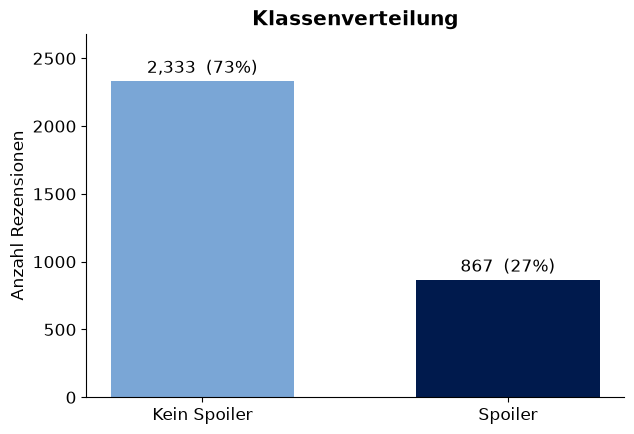

In [ ]:
counts = reviews["label"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(["Kein Spoiler", "Spoiler"], counts.values, color=[LIGHT, BLUE], width=0.6)
ax.bar_label(bars, labels=[f"{v:,}  ({v / len(reviews):.0%})" for v in counts.values], padding=3)
ax.set(title="Klassenverteilung", ylabel="Anzahl Rezensionen", ylim=(0, counts.max() * 1.15))
show(fig, "01_klassenverteilung")

Der Spoiler-Anteil in den zehn häufigsten Genres. Die rote Linie ist der Anteil im gesamten Datensatz.

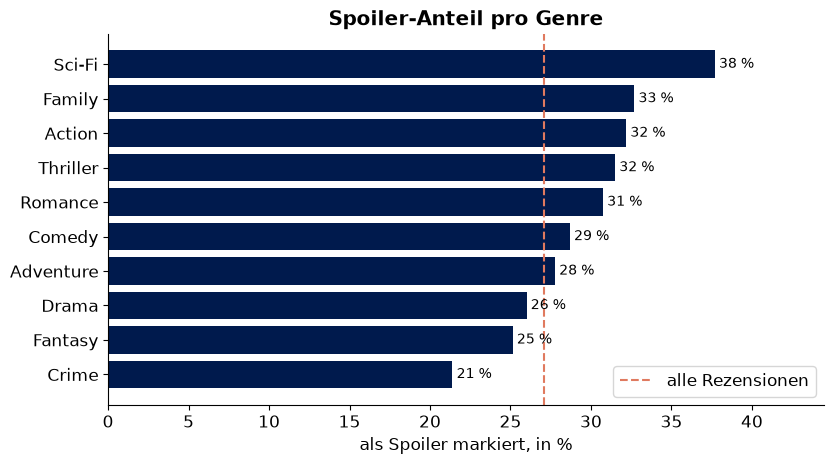

In [ ]:
overall = reviews["label"].mean() * 100
by_genre = (reviews.explode("genre").dropna(subset=["genre"])
            .groupby("genre")["label"].agg(["size", "mean"])
            .sort_values("size", ascending=False).head(10).sort_values("mean"))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(by_genre.index, by_genre["mean"] * 100, color=BLUE)
ax.bar_label(bars, fmt="%.0f %%", padding=3, fontsize=10)
ax.axvline(overall, color=RED, ls="--", label="alle Rezensionen")
ax.set(title="Spoiler-Anteil pro Genre", xlabel="als Spoiler markiert, in %",
       xlim=(0, by_genre["mean"].max() * 118))
ax.legend(loc="lower right")
show(fig, "02_spoiler_pro_genre")

Der Spoiler-Anteil getrennt für Rezensionen ohne und mit Spoiler-Wort:

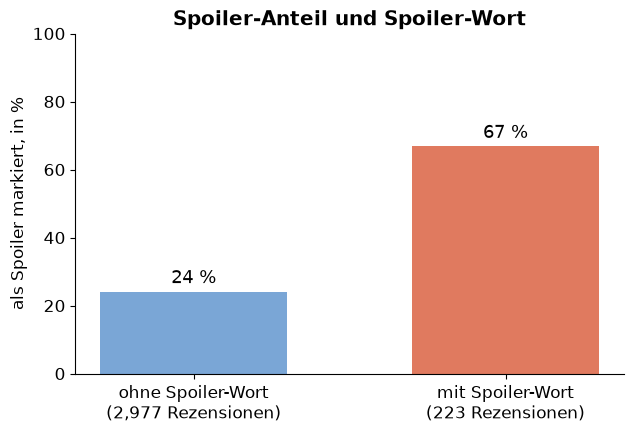

Spoiler-Anteil ohne Spoiler-Wort: 24.1 %
Spoiler-Anteil mit Spoiler-Wort:  66.8 %


In [ ]:
by_word = reviews.groupby("has_spoiler_word")["label"].agg(["size", "mean"])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
labels = [f"ohne Spoiler-Wort\n({by_word.at[False, 'size']:,} Rezensionen)",
          f"mit Spoiler-Wort\n({by_word.at[True, 'size']:,} Rezensionen)"]
shares = [by_word.at[False, "mean"] * 100, by_word.at[True, "mean"] * 100]
bars = ax.bar(labels, shares, color=[LIGHT, RED], width=0.6)
ax.bar_label(bars, fmt="%.0f %%", padding=3, fontsize=13)
ax.set(title="Spoiler-Anteil und Spoiler-Wort", ylabel="als Spoiler markiert, in %", ylim=(0, 100))
show(fig, "03_spoiler_wort")

print(f"Spoiler-Anteil ohne Spoiler-Wort: {shares[0]:.1f} %")
print(f"Spoiler-Anteil mit Spoiler-Wort:  {shares[1]:.1f} %")

### Warum wir das Spoiler-Wort entfernen

Wer seine Rezension als Spoiler markiert, schreibt oft auch die Warnung in den Text. Ein Modell könnte also einfach dieses eine Wort lernen. Das wäre keine Erkennung an der Wortwahl über die Handlung, und es wäre unfair gegenüber allen Rezensionen ohne Warnung.

Deshalb löschen wir das Spoiler-Wort aus allen Texten, bevor wir trainieren. Die Funktion dafür:

In [ ]:
def remove_spoiler_word(texts):
    return texts.str.replace(SPOILER_WORD, " ", regex=True)


example = pd.Series(["SPOILER ALERT! In the end he dies. No spoilers here, I promise."])
print("Vorher: ", example[0])
print("Nachher:", remove_spoiler_word(example)[0])

Vorher:  SPOILER ALERT! In the end he dies. No spoilers here, I promise.
Nachher:  ! In the end he dies.   here, I promise.


## 3 · Die Forschungsfrage

### 3.1 Unser Vorgehen

**Zwei Aufteilungen.** Einmal verteilen wir die Rezensionen *zufällig* auf Training, Validierung und Test (70 / 15 / 15 %). Einmal teilen wir *nach Film*: Kein Film aus dem Test kommt im Training vor. Die zweite Variante brauchen wir für den Teil „auch bei unbekannten Filmen“.

**Zwei Arten von Merkmalen.**

- *Bag of Words:* wie oft jedes Wort und jedes Wortpaar vorkommt
- *TF-IDF:* dasselbe, aber Wörter, die in fast jeder Rezension stehen, zählen weniger

**Drei Modelle.** Naive Bayes, logistische Regression und eine lineare SVM.

**Abstimmung.** Für jedes Modell probieren wir drei Werte seines wichtigsten Hyperparameters und nehmen den, der auf der Validierungsmenge am besten abschneidet. Dort stellen wir auch die Entscheidungsschwelle ein. Die Testmenge fassen wir erst ganz am Ende an.

**Metriken.** Accuracy, Precision, Recall, F1 und ROC-AUC. Precision, Recall und F1 beziehen sich auf die Klasse „Spoiler“.

Zuerst ziehen wir die Stichprobe und entfernen das Spoiler-Wort:

In [ ]:
n_sample = len(reviews) if SAMPLE_SIZE is None else min(SAMPLE_SIZE, len(reviews))
sample = reviews.sample(n_sample, random_state=SEED).reset_index(drop=True)

sample["text"] = remove_spoiler_word(sample["review_text"])

print(f"{len(sample):,} Rezensionen in der Stichprobe")

3,200 Rezensionen in der Stichprobe


Dann die beiden Aufteilungen:

In [ ]:
def split_random(df, seed=SEED):
    train, rest = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=seed)
    val, test = train_test_split(rest, test_size=0.5, stratify=rest["label"], random_state=seed)
    return {"train": train, "val": val, "test": test}


def split_by_film(df, seed=SEED):
    # GroupShuffleSplit hält alle Rezensionen eines Films zusammen
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    i_train, i_rest = next(splitter.split(df, groups=df["movie_id"]))
    train, rest = df.iloc[i_train], df.iloc[i_rest]

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
    i_val, i_test = next(splitter.split(rest, groups=rest["movie_id"]))
    return {"train": train, "val": rest.iloc[i_val], "test": rest.iloc[i_test]}


SPLITS = {"Zufällig": split_random(sample), "Nach Film": split_by_film(sample)}

# Kontrolle: Wie viele Testrezensionen gehören zu Filmen aus dem Training?
for name, parts in SPLITS.items():
    known = parts["test"]["movie_id"].isin(parts["train"]["movie_id"])
    print(f"{name:10s} {len(parts['train']):,} Training · {len(parts['val']):,} Validierung · "
          f"{len(parts['test']):,} Test · {known.mean():.0%} davon aus bekannten Filmen")

Zufällig   2,240 Training · 480 Validierung · 480 Test · 100% davon aus bekannten Filmen
Nach Film  2,080 Training · 360 Validierung · 760 Test · 0% davon aus bekannten Filmen


Die Merkmale. Beide Varianten nutzen dieselben Wörter und Wortpaare, damit der Vergleich fair ist.

In [ ]:
WORDS = dict(lowercase=True,
             token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",   # nur Wörter aus Buchstaben
             ngram_range=(1, 2),                        # Wörter und Wortpaare
             min_df=5, max_df=0.9,                      # sehr seltene und sehr häufige raus
             max_features=200_000,
             dtype=np.float32)


def make_bow():
    return CountVectorizer(**WORDS)


def make_tfidf():
    # sublinear_tf dämpft häufige Wiederholungen eines Wortes
    return TfidfVectorizer(sublinear_tf=True, **WORDS)


FEATURES = {"Bag of Words": make_bow, "TF-IDF": make_tfidf}

Die Modelle und die Werte, die wir für sie ausprobieren.

Bag of Words liefert viel größere Zahlen als TF-IDF. Deshalb brauchen logistische Regression und SVM dort eine stärkere Regularisierung, also ein kleineres `C`.

In [ ]:
def make_model(name, value):
    if name == "Naive Bayes":
        return ComplementNB(alpha=value)
    if name == "Logistische Regression":
        return LogisticRegression(C=value, class_weight="balanced",
                                  solver="liblinear", max_iter=2000)
    return LinearSVC(C=value, class_weight="balanced", random_state=SEED)


MODELS = ["Naive Bayes", "Logistische Regression", "Lineare SVM"]
COLORS = {"Naive Bayes": GREY, "Logistische Regression": BLUE, "Lineare SVM": LIGHT}

VALUES = {
    ("Bag of Words", "Naive Bayes"): [0.1, 0.3, 1.0],
    ("Bag of Words", "Logistische Regression"): [0.0003, 0.001, 0.003],
    ("Bag of Words", "Lineare SVM"): [0.00003, 0.0001, 0.0003],
    ("TF-IDF", "Naive Bayes"): [0.03, 0.1, 0.3],
    ("TF-IDF", "Logistische Regression"): [0.3, 1.0, 3.0],
    ("TF-IDF", "Lineare SVM"): [0.03, 0.1, 0.3],
}

Drei kleine Hilfsfunktionen für die Auswertung:

In [ ]:
def get_scores(model, X):
    # Je höher der Score, desto eher hält das Modell die Rezension für einen Spoiler
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def best_threshold(y, scores):
    # Die Schwelle mit dem besten F1 (bestimmen wir nur auf der Validierungsmenge)
    precision, recall, thresholds = precision_recall_curve(y, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]


def all_metrics(y, pred, scores):
    return {"Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, scores)}

### 3.2 Training und Test ⏳

Diese Zelle braucht etwa 5 Minuten. Für jede Kombination aus Aufteilung, Merkmalen und Modell passiert dasselbe:

1. Merkmale aus dem Training lernen
2. das Modell mit jedem der drei Werte trainieren und den besten auf der Validierung wählen
3. die Schwelle auf der Validierung einstellen
4. einmal auf dem Test bewerten

In [ ]:
start = time.time()
runs = {}     # alle Ergebnisse, Schlüssel: (Aufteilung, Merkmale, Modell)

for split_name, parts in SPLITS.items():
    y_train = parts["train"]["label"]
    y_val = parts["val"]["label"]
    y_test = parts["test"]["label"].to_numpy()

    for feature_name, make_features in FEATURES.items():
        vectorizer = make_features()
        X_train = vectorizer.fit_transform(parts["train"]["text"])
        X_val = vectorizer.transform(parts["val"]["text"])
        X_test = vectorizer.transform(parts["test"]["text"])

        for model_name in MODELS:
            # den besten Hyperparameter auf der Validierung suchen
            best_model, best_value, best_auc = None, None, -1
            for value in VALUES[(feature_name, model_name)]:
                model = make_model(model_name, value).fit(X_train, y_train)
                auc = roc_auc_score(y_val, get_scores(model, X_val))
                if auc > best_auc:
                    best_model, best_value, best_auc = model, value, auc

            threshold = best_threshold(y_val, get_scores(best_model, X_val))
            scores = get_scores(best_model, X_test)
            pred = (scores >= threshold).astype(int)

            runs[(split_name, feature_name, model_name)] = {
                "model": best_model, "vectorizer": vectorizer, "param": best_value,
                "scores": scores, "pred": pred, **all_metrics(y_test, pred, scores)}

        print(f"{split_name}, {feature_name}: fertig nach {(time.time() - start) / 60:.0f} min")

    # Zum Vergleich: ein "Modell", das einfach immer Spoiler sagt
    ones = np.ones(len(y_test))
    runs[(split_name, "–", "Immer Spoiler")] = {
        "scores": ones, "pred": ones.astype(int),
        **all_metrics(y_test, ones.astype(int), ones)}

Zufällig, Bag of Words: fertig nach 0 min
Zufällig, TF-IDF: fertig nach 0 min
Nach Film, Bag of Words: fertig nach 0 min
Nach Film, TF-IDF: fertig nach 0 min


### 3.3 Ergebnisse

Alle Werte stammen von der Testmenge. Je dunkler ein Feld, desto höher der Wert in dieser Spalte.

In [ ]:
results = pd.DataFrame(
    [{"Aufteilung": s, "Merkmale": f, "Modell": m, **{k: run[k] for k in METRICS}}
     for (s, f, m), run in runs.items()]
).set_index(["Aufteilung", "Merkmale", "Modell"])

results.to_csv(FIG_DIR / "ergebnisse.csv")
#results.style.format("{:.3f}").background_gradient(cmap="Blues", subset=["F1", "ROC-AUC"])

Dieselben Zahlen als Grafiken, eine pro Aufteilung und Merkmalsart. Die rote Linie ist der Vergleichswert „immer Spoiler“.

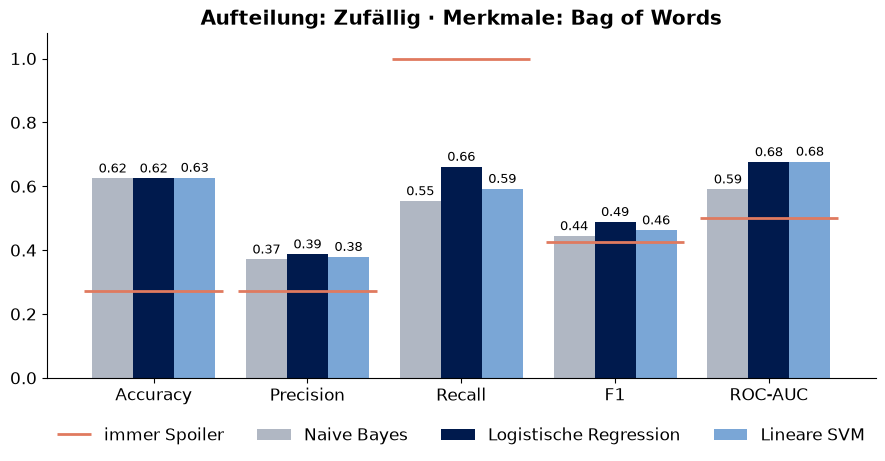

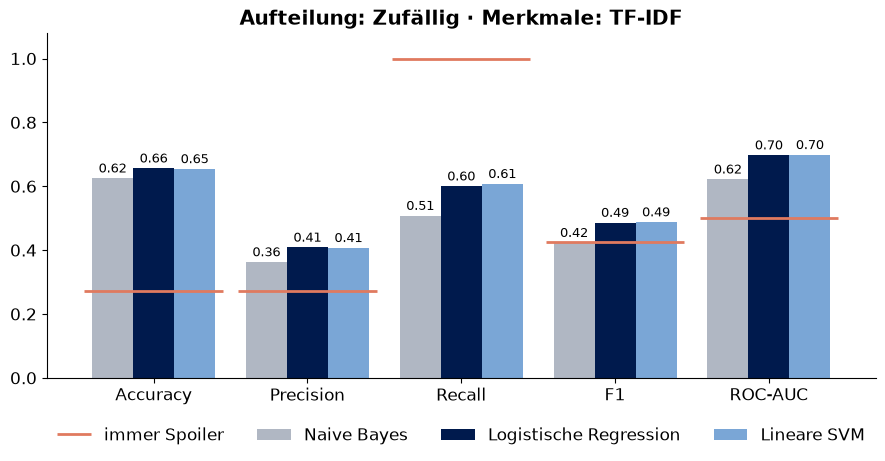

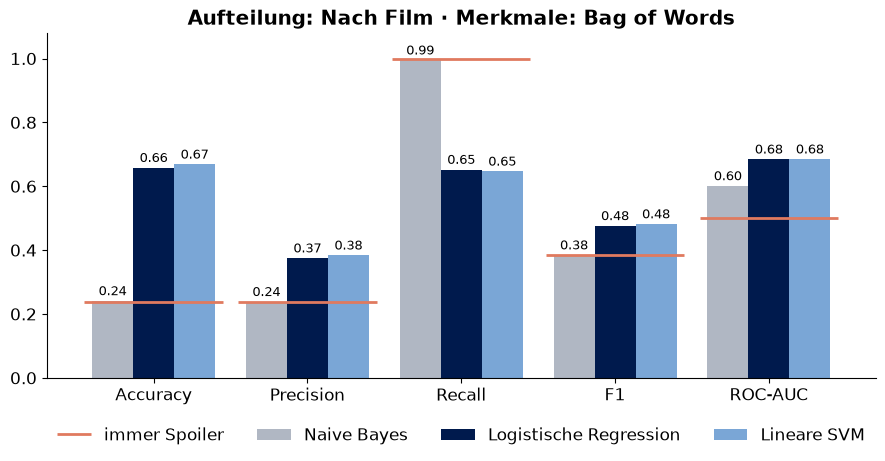

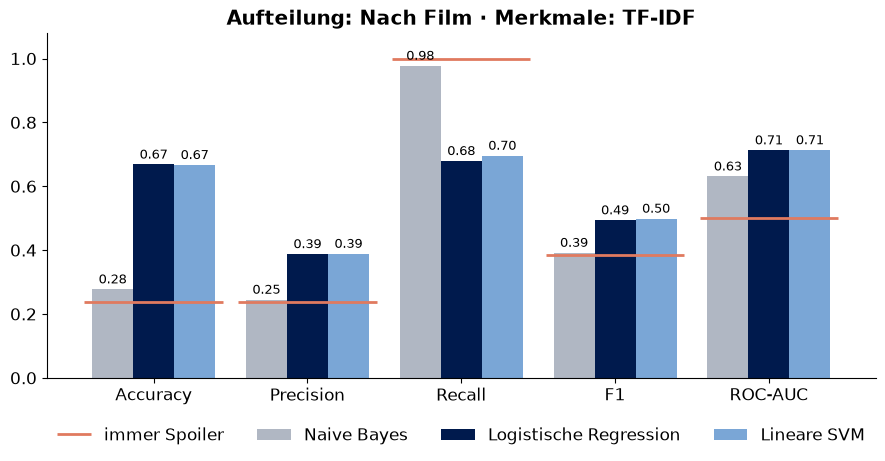

In [ ]:
number = 4
for split_name in SPLITS:
    for feature_name in FEATURES:
        groups = {m: runs[(split_name, feature_name, m)] for m in MODELS}
        fig = metric_bars(groups, [COLORS[m] for m in MODELS],
                          f"Aufteilung: {split_name} · Merkmale: {feature_name}",
                          baseline=runs[(split_name, "–", "Immer Spoiler")])
        file_name = f"{number:02d}_metriken_{split_name}_{feature_name}".lower().replace(" ", "_")
        show(fig, file_name.replace("ä", "ae"))
        number += 1

### 3.4 Ein Modell im Detail

Ab hier arbeiten wir mit der **logistischen Regression** auf **TF-IDF** und **unbekannten Filmen**. Die logistische Regression nehmen wir, weil wir ihre Gewichte direkt lesen können. Das brauchen wir für H1.

Die erste Zelle zeichnet die Konfusionsmatrix dieses Modells, die zweite die ROC-Kurven aller drei Modelle auf TF-IDF.

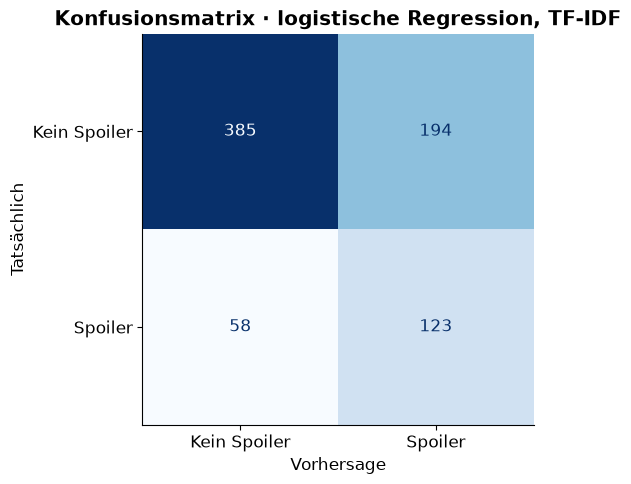

In [ ]:
MAIN = ("Nach Film", "TF-IDF", "Logistische Regression")
main = runs[MAIN]
test = SPLITS["Nach Film"]["test"]
y_test = test["label"].to_numpy()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, main["pred"], display_labels=["Kein Spoiler", "Spoiler"],
    cmap="Blues", colorbar=False, ax=ax)
ax.set(title="Konfusionsmatrix · logistische Regression, TF-IDF",
       xlabel="Vorhersage", ylabel="Tatsächlich")
show(fig, "08_konfusionsmatrix")

for metric in METRICS:
    messwerte[f"3 · {metric} (unbekannte Filme, TF-IDF, LogReg)"] = f"{main[metric]:.3f}"

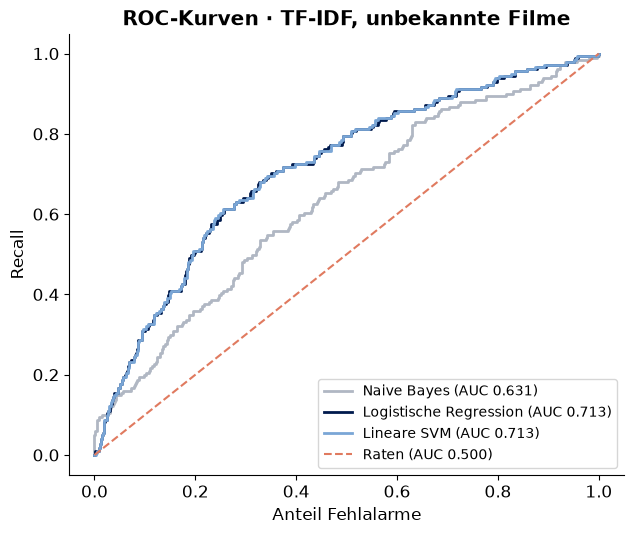

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for model_name in MODELS:
    run = runs[("Nach Film", "TF-IDF", model_name)]
    false_alarms, recall, _ = roc_curve(y_test, run["scores"])
    ax.plot(false_alarms, recall, color=COLORS[model_name], lw=2,
            label=f"{model_name} (AUC {run['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=RED, ls="--", label="Raten (AUC 0.500)")
ax.set(title="ROC-Kurven · TF-IDF, unbekannte Filme",
       xlabel="Anteil Fehlalarme", ylabel="Recall")
ax.legend(loc="lower right", fontsize=10)
show(fig, "09_roc_kurven")

**Bootstrap.** Um die Unsicherheit abzuschätzen, ziehen wir die Testmenge 1.000-mal neu (mit Zurücklegen) und berechnen jedes Mal, wie viel F1 das Modell über dem Vergleichswert „immer Spoiler“ liegt. Ausgegeben werden der Mittelwert und der Bereich, in dem 95 % der Wiederholungen liegen.

In [ ]:
baseline = runs[("Nach Film", "–", "Immer Spoiler")]

rng = np.random.default_rng(SEED)
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    diffs.append(f1_score(y_test[i], main["pred"][i]) - f1_score(y_test[i], baseline["pred"][i]))

low, high = np.quantile(diffs, [0.025, 0.975])
print(f"F1 des Modells:            {main['F1']:.3f}")
print(f"F1 von 'immer Spoiler':    {baseline['F1']:.3f}")
print(f"Vorsprung:                 {np.mean(diffs):+.3f}   (95 %: {low:+.3f} bis {high:+.3f})")

messwerte["3 · F1-Vorsprung auf „immer Spoiler“"] = f"{np.mean(diffs):+.3f}  ({low:+.3f} bis {high:+.3f})"

F1 des Modells:            0.494
F1 von 'immer Spoiler':    0.385
Vorsprung:                 +0.109   (95 %: +0.063 bis +0.153)


**Kontrolle: Was hätte das Spoiler-Wort gebracht?** Wir trainieren dasselbe Modell noch einmal auf dem Originaltext, also mit Spoiler-Wort, und vergleichen.

In [ ]:
C_BEST = main["param"]


def train_and_test(train, test, col, val=None):
    # Logistische Regression auf TF-IDF trainieren und auf `test` bewerten.
    # Ohne Validierungsmenge nutzen wir die Standardschwelle (Score 0).
    tfidf = make_tfidf()
    model = make_model("Logistische Regression", C_BEST)
    model.fit(tfidf.fit_transform(train[col]), train["label"])

    scores = model.decision_function(tfidf.transform(test[col]))
    threshold = 0.0
    if val is not None:
        val_scores = model.decision_function(tfidf.transform(val[col]))
        threshold = best_threshold(val["label"], val_scores)
    return all_metrics(test["label"], (scores >= threshold).astype(int), scores)


parts = SPLITS["Nach Film"]
with_word = train_and_test(parts["train"], parts["test"], "review_text", parts["val"])

print("                    F1      ROC-AUC")
print(f"ohne Spoiler-Wort   {main['F1']:.3f}   {main['ROC-AUC']:.3f}")
print(f"mit Spoiler-Wort    {with_word['F1']:.3f}   {with_word['ROC-AUC']:.3f}")

messwerte["3 · F1 mit Spoiler-Wort (zum Vergleich)"] = f"{with_word['F1']:.3f}"
messwerte["3 · ROC-AUC mit Spoiler-Wort (zum Vergleich)"] = f"{with_word['ROC-AUC']:.3f}"

                    F1      ROC-AUC
ohne Spoiler-Wort   0.494   0.713
mit Spoiler-Wort    0.501   0.720


### 3.5 Hilft es, nur ein Genre oder nur einen Film zu betrachten?

Bisher lernt ein Modell aus allen Filmen gemeinsam. Hier prüfen wir, ob ein spezialisiertes Modell besser ist.

**Pro Genre.** Für die vier häufigsten Genres trainieren wir ein Modell (logistische Regression, TF-IDF) nur auf Rezensionen dieses Genres und eines auf gleich vielen zufälligen Rezensionen aller Genres. Getestet wird auf den unbekannten Filmen des Genres.

In [ ]:
train_film = SPLITS["Nach Film"]["train"]
test_film = SPLITS["Nach Film"]["test"]

genre_rows = []
top_genres = sample.explode("genre")["genre"].value_counts().head(4).index

for genre in top_genres:
    train_g = train_film[train_film["genre"].apply(lambda g: genre in g)]
    test_g = test_film[test_film["genre"].apply(lambda g: genre in g)]
    if len(test_g) < 100 or test_g["label"].nunique() < 2 or train_g["label"].nunique() < 2:
        continue

    same_size = train_film.sample(len(train_g), random_state=SEED)
    genre_rows.append({"Gruppe": genre, "Training": "nur dieses Genre",
                       **train_and_test(train_g, test_g, "text")})
    genre_rows.append({"Gruppe": genre, "Training": "alle Genres",
                       **train_and_test(same_size, test_g, "text")})

genre_result = pd.DataFrame(genre_rows)
print("Genres fertig:", ", ".join(genre_result["Gruppe"].unique()))

Genres fertig: Drama, Adventure, Comedy


Die Grafik zeigt alle Metriken als Mittelwert über die Genres. Die Tabelle darunter zeigt jedes Genre einzeln.

In diesem Abschnitt gibt es keine eigene Validierungsmenge. Deshalb nutzen wir hier die Standardschwelle der logistischen Regression.

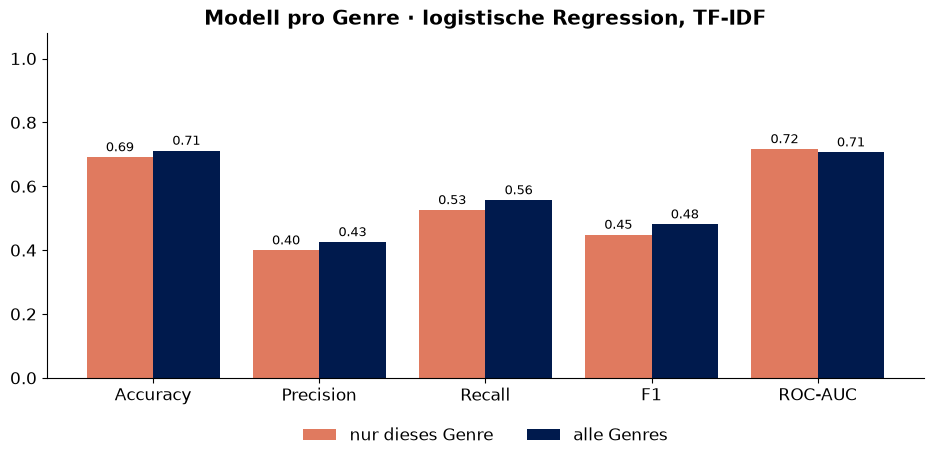

Accuracy  Precision  Recall    F1  ROC-AUC
Genre     Training                                                    
Drama     nur dieses Genre     0.713      0.393   0.548 0.458    0.709
          alle Genres          0.713      0.393   0.548 0.458    0.699
Adventure nur dieses Genre     0.670      0.352   0.588 0.440    0.688
          alle Genres          0.715      0.396   0.563 0.465    0.716
Comedy    nur dieses Genre     0.692      0.455   0.441 0.448    0.753
          alle Genres          0.708      0.487   0.559 0.521    0.705

In [ ]:
genre_mean = genre_result.groupby("Training", sort=False)[METRICS].mean()

fig = metric_bars({name: genre_mean.loc[name] for name in genre_mean.index}, [RED, BLUE],
                  "Modell pro Genre · logistische Regression, TF-IDF")
show(fig, "10_genre_metriken")

genre_table = genre_result.set_index(["Gruppe", "Training"])[METRICS].rename_axis(["Genre", "Training"])
genre_table.to_csv(FIG_DIR / "genre.csv")
display(genre_table)

for name in genre_mean.index:
    messwerte[f"3 · F1, Training „{name}“"] = f"{genre_mean.at[name, 'F1']:.3f}"
    messwerte[f"3 · ROC-AUC, Training „{name}“"] = f"{genre_mean.at[name, 'ROC-AUC']:.3f}"

**Pro Film** ⏳ etwa 6 Minuten

Für die drei meistrezensierten Filme vergleichen wir per 5-facher Kreuzvalidierung drei Varianten:

- **nur dieser Film:** das Modell lernt nur aus Rezensionen dieses Films
- **alle anderen Filme:** das Modell hat diesen Film nie gesehen
- **alle Filme:** das Modell kennt die anderen Filme und diesen

In [ ]:
film_rows = []
counts = reviews["movie_id"].value_counts().head(3)
big_films = [movie_id for movie_id, n in counts.items() if n >= 300]

for movie_id in big_films:
    film = reviews[reviews["movie_id"] == movie_id].copy()
    film["text"] = remove_spoiler_word(film["review_text"])

    others = sample[sample["movie_id"] != movie_id]
    general = others.sample(min(20_000, len(others)), random_state=SEED)

    folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
    for fold, (i_fit, i_check) in enumerate(folds.split(film, film["label"])):
        fit, check = film.iloc[i_fit], film.iloc[i_check]
        variants = {"nur dieser Film": fit,
                    "alle anderen Filme": general,
                    "alle Filme": pd.concat([general, fit])}
        for name, train_data in variants.items():
            film_rows.append({"Gruppe": movie_id, "Falte": fold, "Training": name,
                              **train_and_test(train_data, check, "text")})
    print(f"{movie_id} fertig")

film_result = pd.DataFrame(film_rows)
if len(film_result) == 0:
    print("Übersprungen: In den Beispieldaten hat kein Film genug Rezensionen.")

tt0167260 fertig
tt0068646 fertig


Wieder zuerst alle Metriken als Mittelwert (über die Filme und Falten), dann die Tabelle pro Film.

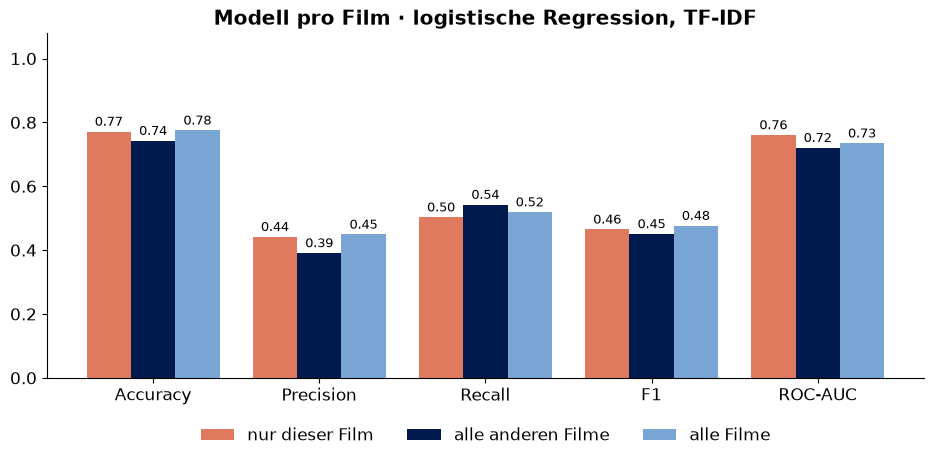

Accuracy  Precision  Recall    F1  ROC-AUC
Film      Training                                                      
tt0167260 nur dieser Film        0.782      0.485   0.551 0.508    0.785
          alle anderen Filme     0.733      0.404   0.632 0.492    0.726
          alle Filme             0.778      0.477   0.597 0.526    0.761
tt0068646 nur dieser Film        0.760      0.398   0.454 0.421    0.736
          alle anderen Filme     0.753      0.378   0.453 0.408    0.715
          alle Filme             0.772      0.421   0.441 0.427    0.708

In [ ]:
if len(film_result) > 0:
    film_mean = film_result.groupby("Training", sort=False)[METRICS].mean()

    fig = metric_bars({name: film_mean.loc[name] for name in film_mean.index}, [RED, BLUE, LIGHT],
                      "Modell pro Film · logistische Regression, TF-IDF")
    show(fig, "11_film_metriken")

    film_table = (film_result.groupby(["Gruppe", "Training"], sort=False)[METRICS].mean()
                  .rename_axis(["Film", "Training"]))
    film_table.to_csv(FIG_DIR / "film.csv")
    display(film_table)

    for name in film_mean.index:
        messwerte[f"3 · F1, Training „{name}“"] = f"{film_mean.at[name, 'F1']:.3f}"
        messwerte[f"3 · ROC-AUC, Training „{name}“"] = f"{film_mean.at[name, 'ROC-AUC']:.3f}"

### Zusatzexperiment: Helfen Plot-Hinweise bei Der Pate?

Die Datei `data/example/wikipedia_plot_hints.json` wurde mit generativer KI aus einem bereitgestellten englischen Wikipedia-Plottext zu *The Godfather* (Francis Ford Coppola, 1972; IMDb `tt0068646`) erstellt. Der Prompt bat darum, Figuren samt Namensvarianten sowie wichtige Ereignisse und passende Suchbegriffe als JSON zu extrahieren. Die KI sollte nur den bereitgestellten Plottext verwenden; Rezensionen und deren Spoiler-Labels wurden nicht mitgegeben. Das Feld `spoiler_sensitive` aus der KI-Ausgabe wird im Experiment nicht verwendet.

Wir vergleichen in einer stratifizierten 5-fachen Kreuzvalidierung zwei logistische TF-IDF-Modelle: eines mit dem Rezensionstext allein und eines mit dem Rezensionstext plus Plot-Hinweisen. Die Hinweise bestehen aus einem Signal, ob eine Figur erwähnt wird, und je einem Signal pro Plot-Ereignis. Ein Ereignis zählt nur als Treffer, wenn sowohl eine dazugehörige Figur als auch ein weiterer Ereignisbegriff vorkommen. Das Modell lernt aus den vorhandenen Spoiler-Labels, welche Treffer hilfreich sind. Beide Varianten verwenden dieselben Folds, C = 1 und die Standardschwelle 0. Das Ergebnis gilt nur für den bekannten Film Der Pate.

In [ ]:
import json
from scipy.sparse import csr_matrix, hstack

PLOT_HINT_MOVIE_ID = "tt0068646"
plot_hints_path = DATA_DIR / "example" / "wikipedia_plot_hints.json"
with plot_hints_path.open(encoding="utf-8") as file:
    plot_hints = json.load(file)

plot_film = sample.loc[sample["movie_id"].eq(PLOT_HINT_MOVIE_ID)].copy().reset_index(drop=True)
if plot_film.empty:
    raise ValueError(f"Keine Rezensionen für Film {PLOT_HINT_MOVIE_ID} in der Stichprobe gefunden.")
label_counts = plot_film["label"].value_counts()
if plot_film["label"].nunique() != 2 or label_counts.min() < 5:
    raise ValueError("Für eine stratifizierte 5-fache Kreuzvalidierung braucht jede Klasse mindestens 5 Rezensionen.")
if not plot_hints.get("characters") or not plot_hints.get("key_events"):
    raise ValueError("Die Plot-Hinweisdatei muss Figuren und Handlungselemente enthalten.")

def contains_plot_term(text, term):
    term = str(term).strip()
    if not term:
        return False
    pattern = rf"(?<!\w){re.escape(term)}(?!\w)"
    return bool(re.search(pattern, str(text), flags=re.IGNORECASE))

character_terms = [
    tuple(dict.fromkeys([character["name"], *character.get("aliases", [])]))
    for character in plot_hints["characters"]
]
known_character_terms = {
    str(term).casefold()
    for character in plot_hints["characters"]
    for term in [character["name"], *character.get("aliases", [])]
}
event_terms = []
for event in plot_hints["key_events"]:
    terms = tuple(dict.fromkeys(event.get("terms", [])))
    character_terms_for_event = tuple(
        term for term in terms if str(term).casefold() in known_character_terms)
    detail_terms_for_event = tuple(
        term for term in terms if str(term).casefold() not in known_character_terms)
    if not character_terms_for_event or not detail_terms_for_event:
        raise ValueError("Jedes Plot-Ereignis braucht Figuren- und Ereignisbegriffe.")
    event_terms.append((character_terms_for_event, detail_terms_for_event))

def plot_features_for_review(text):
    character_mentioned = int(
        any(contains_plot_term(text, term)
            for character in character_terms for term in character)
    )
    event_mentions = []
    for character_terms_for_event, detail_terms_for_event in event_terms:
        character_hit = any(
            contains_plot_term(text, term) for term in character_terms_for_event)
        detail_hit = any(
            contains_plot_term(text, term) for term in detail_terms_for_event)
        event_mentions.append(int(character_hit and detail_hit))
    return [character_mentioned, *event_mentions]

plot_feature_matrix = np.asarray(
    [plot_features_for_review(text) for text in plot_film["text"].fillna("")],
    dtype=np.float32,
)
print(f"Rezensionen zu Der Pate: {len(plot_film):,}")
print(f"Mit mindestens einem Plot-Ereignis-Treffer: "
      f"{(plot_feature_matrix[:, 1:].sum(axis=1) > 0).sum():,}")

plot_hint_rows = []
plot_hint_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (i_train, i_test) in enumerate(
        plot_hint_folds.split(plot_film["text"], plot_film["label"]), start=1):
    train_film = plot_film.iloc[i_train]
    test_film = plot_film.iloc[i_test]
    y_train = train_film["label"].to_numpy()
    y_test = test_film["label"].to_numpy()

    vectorizer = make_tfidf()
    X_train_text = vectorizer.fit_transform(train_film["text"])
    X_test_text = vectorizer.transform(test_film["text"])
    X_train_plus_hints = hstack(
        [X_train_text, csr_matrix(plot_feature_matrix[i_train])], format="csr")
    X_test_plus_hints = hstack(
        [X_test_text, csr_matrix(plot_feature_matrix[i_test])], format="csr")

    variants = {
        "Nur Rezensionstext": (X_train_text, X_test_text),
        "Rezensionstext + Plot-Hinweise": (X_train_plus_hints, X_test_plus_hints),
    }
    for variant, (X_train, X_test) in variants.items():
        model = make_model("Logistische Regression", 1.0).fit(X_train, y_train)
        scores = get_scores(model, X_test)
        predictions = (scores >= 0).astype(int)
        plot_hint_rows.append({
            "Falte": fold,
            "Variante": variant,
            **all_metrics(y_test, predictions, scores),
        })

plot_hint_result = pd.DataFrame(plot_hint_rows)
plot_hint_summary = plot_hint_result.groupby("Variante", sort=False)[METRICS].agg(["mean", "std"])
plot_hint_result.to_csv(FIG_DIR / "plot_hints_der_pate_folds.csv", index=False)
plot_hint_summary.to_csv(FIG_DIR / "plot_hints_der_pate_summary.csv")
display(plot_hint_summary.round(3))

Rezensionen zu Der Pate: 400
Mit mindestens einem Plot-Ereignis-Treffer: 34


Accuracy       Precision       Recall        \
                                   mean   std      mean   std   mean   std   
Variante                                                                     
Nur Rezensionstext                0.765 0.019     0.392 0.065  0.380 0.133   
Rezensionstext + Plot-Hinweise    0.692 0.047     0.327 0.058  0.545 0.187   

                                  F1       ROC-AUC        
                                mean   std    mean   std  
Variante                                                  
Nur Rezensionstext             0.382 0.099   0.735 0.077  
Rezensionstext + Plot-Hinweise 0.402 0.101   0.745 0.064

## 4 · H1 · Handlung statt Meinung

Die logistische Regression gibt jedem Wort ein Gewicht. Positiv heißt: spricht für Spoiler. Negativ heißt: spricht dagegen.

Die Zelle zeigt die 15 stärksten Wörter auf jeder Seite, jeweils als eigene Grafik. Modell: logistische Regression auf TF-IDF, unbekannte Filme.

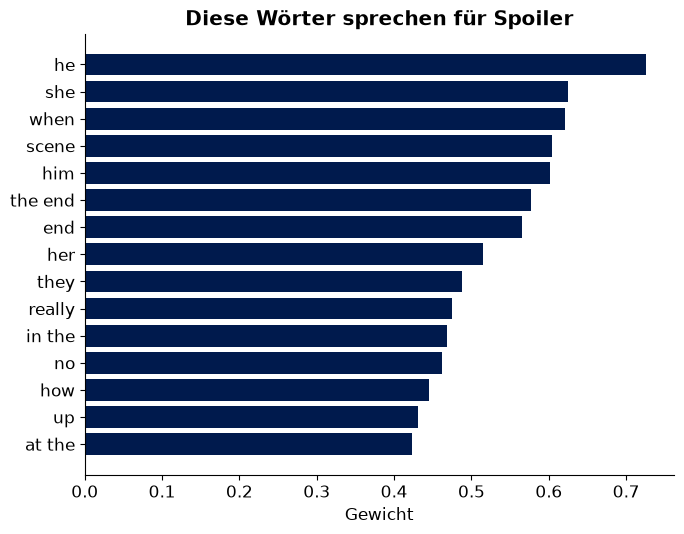

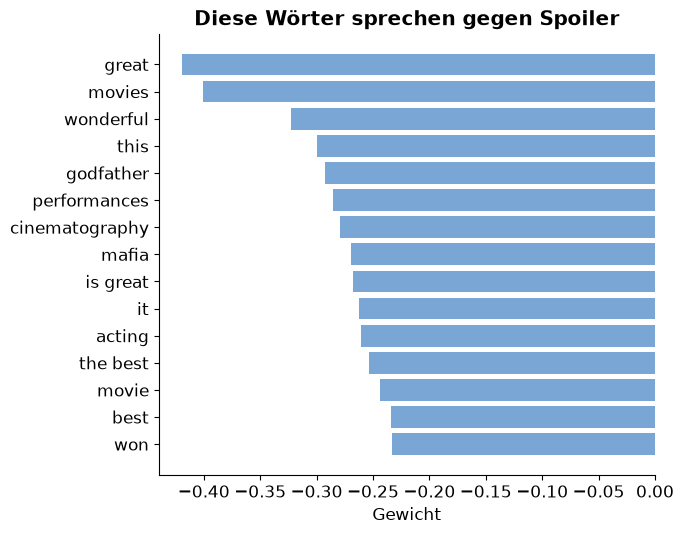

Für Spoiler:   he, she, when, scene, him, the end, end, her, they, really, in the, no, how, up, at the
Gegen Spoiler: great, movies, wonderful, this, godfather, performances, cinematography, mafia, is great, it, acting, the best, movie, best, won


In [ ]:
words = main["vectorizer"].get_feature_names_out()
weights = pd.Series(main["model"].coef_.ravel(), index=words).sort_values()

top = weights.tail(15)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top.values, color=BLUE)
ax.set(title="Diese Wörter sprechen für Spoiler", xlabel="Gewicht")
show(fig, "12_h1_fuer_spoiler")

bottom = weights.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(bottom.index, bottom.values, color=LIGHT)
ax.set(title="Diese Wörter sprechen gegen Spoiler", xlabel="Gewicht")
show(fig, "13_h1_gegen_spoiler")

print("Für Spoiler:  ", ", ".join(top.index[::-1]))
print("Gegen Spoiler:", ", ".join(bottom.index[::-1]))

**Zwei Wortlisten.** Zusätzlich vergleichen wir die Gewichte von 30 Handlungswörtern mit denen von 30 Bewertungswörtern. Beide Listen haben wir festgelegt, bevor wir ein Modell trainiert haben, ausgehend von den Beispielen unserer Präsentation.

Die Zelle gibt aus, welcher Anteil jeder Liste das erwartete Vorzeichen hat. Der Mann-Whitney-U-Test prüft, ob die Gewichte der Handlungswörter insgesamt größer sind.

In [ ]:
PLOT_WORDS = ["dies", "die", "died", "death", "dead", "killed", "kills", "kill",
              "murder", "murdered", "ending", "end", "twist", "reveals", "revealed",
              "reveal", "turns out", "betrays", "escape", "secret", "truth", "finale",
              "climax", "survives", "villain", "sacrifice", "discovers", "married",
              "pregnant", "returns"]

OPINION_WORDS = ["acting", "performance", "performances", "recommend", "recommended",
                 "brilliant", "boring", "cast", "director", "cinematography",
                 "soundtrack", "worth", "entertaining", "enjoyable", "masterpiece",
                 "overrated", "funny", "beautiful", "dialogue", "script", "effects",
                 "pacing", "editing", "actors", "actress", "stunning", "disappointing",
                 "excellent", "terrible", "waste"]

w_plot = weights.reindex(PLOT_WORDS).dropna()
w_opinion = weights.reindex(OPINION_WORDS).dropna()
p_value = stats.mannwhitneyu(w_plot, w_opinion, alternative="greater").pvalue

print("Die vier Beispielwörter aus unserer Präsentation:")
for word in ["dies", "reveals", "acting", "recommend"]:
    print(f"   {word:10s} {weights.get(word, np.nan):+.2f}")

print(f"\nHandlungswörter mit positivem Gewicht:    {(w_plot > 0).mean():.0%}")
print(f"Bewertungswörter mit negativem Gewicht:   {(w_opinion < 0).mean():.0%}")
print(f"p-Wert:                                   {p_value:.1e}")

messwerte["H1 · Handlungswörter mit positivem Gewicht"] = f"{(w_plot > 0).mean():.0%}"
messwerte["H1 · Bewertungswörter mit negativem Gewicht"] = f"{(w_opinion < 0).mean():.0%}"
messwerte["H1 · p-Wert (Mann-Whitney-U)"] = f"{p_value:.1e}"

Die vier Beispielwörter aus unserer Präsentation:
   dies       +0.16
   reveals    +0.03
   acting     -0.26
   recommend  +0.01

Handlungswörter mit positivem Gewicht:    97%
Bewertungswörter mit negativem Gewicht:   63%
p-Wert:                                   1.2e-08


## 5 · H2 · Unbekannte Filme und Figurennamen

Die Erwartung hat zwei Teile:

**a)** Unbekannte Filme sind schwerer als bekannte.

**b)** Der Grund sind die Figurennamen.

Um b) zu prüfen, behandeln wir die Namen auf drei Arten:

- **mit Namen:** der Text bleibt, wie er ist
- **ohne Namen:** wir löschen die Figurennamen
- **Platzhalter:** wir ersetzen jeden Namen durch dasselbe Wort `FIGURENNAME`

Als Namenskandidaten verwenden wir die zuvor aus den Film-Plottexten ermittelten Namen sowie die 1000 häufigsten US-Vornamen aus `names_dataset`. Die Erkennung erfolgt über Textübereinstimmungen und ist daher nur eine Heuristik: Ein Treffer ist nicht zwingend ein Figurenname, und tatsächliche Figurennamen können übersehen werden.

Der Platzhalter behält die Information „hier wird eine Figur genannt“, aber nicht, welche.

Modell in diesem Abschnitt: logistische Regression auf TF-IDF.

**Figurennamen finden.** Im Datensatz gibt es keine Liste der Figuren. Wir holen sie aus den Handlungstexten: großgeschriebene Wörter mitten im Satz, die öfter groß als klein vorkommen und nur in wenigen Filmen auftauchen.

In [ ]:
movies["plot"] = movies["plot_summary"].fillna("") + " " + movies["plot_synopsis"].fillna("")

# großgeschriebene Wörter, die nicht am Satzanfang stehen
CAPITALIZED = re.compile(r"(?<![.!?]\s)(?<!^)\b[A-Z][a-zA-Z]{2,}\b")

lower_count, upper_count = Counter(), Counter()
for plot in movies["plot"]:
    lower_count.update(re.findall(r"\b[a-z]{3,}\b", plot))
    upper_count.update(w.lower() for w in CAPITALIZED.findall(plot))


def find_names(plot):
    return {w for w in CAPITALIZED.findall(plot)
            if upper_count[w.lower()] > lower_count[w.lower()]}


candidates = movies["plot"].apply(find_names)

# Wörter, die in vielen Filmen vorkommen ("American"), sind keine Figurennamen
films_per_name = Counter(name for names in candidates for name in names)
max_films = 0.03 * len(movies)
movies["names"] = candidates.apply(
    lambda names: sorted(n for n in names if films_per_name[n] <= max_films))

example_film = reviews["movie_id"].value_counts().index[0]
example_names = movies.set_index("movie_id").at[example_film, "names"]
print(f"Beispiel ({example_film}):", ", ".join(example_names[:12]))

Beispiel (tt0167260): Anduin, Anduril, Angmar, Aragorn, Arwen, Astin, Barad, Bean, Bernard, Bilbo, Bloom, Boromir


Jetzt bauen wir die beiden zusätzlichen Textvarianten:

In [ ]:
sample["text_ohne_namen"] = sample["text"]
sample["text_platzhalter"] = sample["text"]

from names_dataset import NameDataset

firstnames_us = NameDataset().get_top_names(n=1000, country_alpha2="US")["US"]

firstnames = firstnames_us["M"] + firstnames_us["F"]

for movie_id, names in zip(movies["movie_id"], movies["names"]):
    rows = sample.index[sample["movie_id"] == movie_id]

    if len(rows) == 0:
        continue
    names_sorted = sorted(set(names) | set(firstnames), key=len, reverse=True)

    pattern = re.compile(
        r"\b(?:" + "|".join(map(re.escape, names_sorted)) + r")\b(?!['’]t\b)"
    )
    texts = sample.loc[rows, "text"]
    sample.loc[rows, "text_ohne_namen"] = texts.str.replace(pattern, "", regex=True)
    sample.loc[rows, "text_platzhalter"] = texts.str.replace(pattern, "FIGURENNAME", regex=True)



changed = (sample["text_ohne_namen"] != sample["text"]).mean()
print(f"{changed:.0%} der Rezensionen nennen mindestens einen Figurennamen\n")

row = sample[sample["text_ohne_namen"] != sample["text"]].sort_values("n_words").iloc[0]
print("mit Namen:   ", row["text"][:150])
print("ohne Namen:  ", row["text_ohne_namen"][:150])
print("Platzhalter: ", row["text_platzhalter"][:150])

85% der Rezensionen nennen mindestens einen Figurennamen

mit Namen:    sadly this is the final chapterthanks mr. Jackson, you did a great jobsaw the three films one after the other and time flew by, 9hours gone in one glo
ohne Namen:   sadly this is the final chapterthanks mr. , you did a great jobsaw the three films one after the other and time flew by, 9hours gone in one glorious m
Platzhalter:  sadly this is the final chapterthanks mr. FIGURENNAME, you did a great jobsaw the three films one after the other and time flew by, 9hours gone in one


**Training** ⏳ etwa 20 Minuten

Ein einzelner Testlauf kann Glück oder Pech sein. Deshalb wiederholen wir beide Aufteilungen fünfmal mit anderem Zufallsstartwert, jeweils mit allen drei Textvarianten. Das sind 30 Trainingsläufe.

In [ ]:
NAME_VARIANTS = {"mit Namen": "text",
                 "ohne Namen": "text_ohne_namen",
                 "Platzhalter": "text_platzhalter"}

rows = []
for seed in range(N_SEEDS):
    for split_name, split_fn in [("Zufällig", split_random), ("Nach Film", split_by_film)]:
        parts = split_fn(sample, seed=SEED + 1 + seed)
        for variant, col in NAME_VARIANTS.items():
            result = train_and_test(parts["train"], parts["test"], col, parts["val"])
            rows.append({"Durchlauf": seed, "Aufteilung": split_name, "Text": variant, **result})
    print(f"Durchlauf {seed + 1} von {N_SEEDS} fertig")

h2 = pd.DataFrame(rows)

Durchlauf 1 von 5 fertig
Durchlauf 2 von 5 fertig
Durchlauf 3 von 5 fertig
Durchlauf 4 von 5 fertig
Durchlauf 5 von 5 fertig


Die Grafik zeigt den F1-Wert als Mittelwert über die fünf Durchläufe (Punkt) und die Streuung zwischen den Durchläufen (Strich). Die Tabelle darunter enthält alle Metriken.

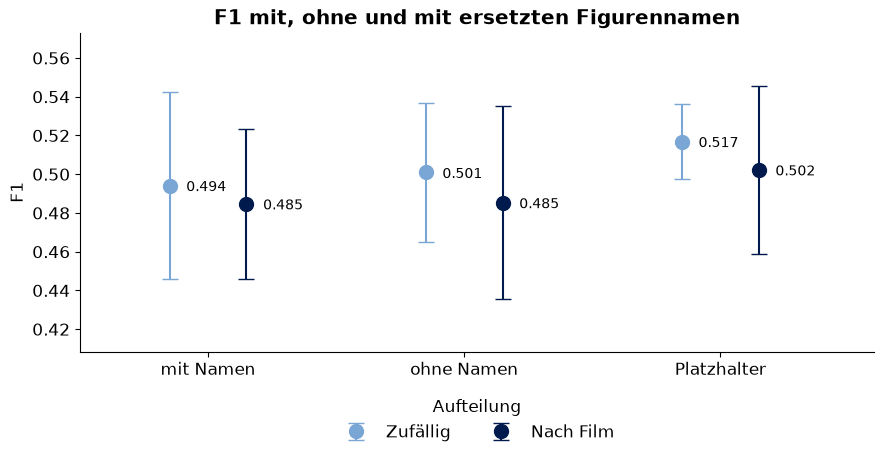

Accuracy  Precision  Recall    F1  ROC-AUC
Text        Aufteilung                                            
mit Namen   Nach Film      0.631      0.381   0.685 0.485    0.721
            Zufällig       0.606      0.381   0.726 0.494    0.711
ohne Namen  Nach Film      0.588      0.369   0.757 0.485    0.719
            Zufällig       0.612      0.388   0.729 0.501    0.713
Platzhalter Nach Film      0.609      0.380   0.770 0.502    0.723
            Zufällig       0.616      0.394   0.757 0.517    0.714

In [ ]:
mean = h2.groupby(["Text", "Aufteilung"])[METRICS].mean()
std = h2.groupby(["Text", "Aufteilung"])["F1"].std()

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(NAME_VARIANTS))

for k, (split_name, color) in enumerate([("Zufällig", LIGHT), ("Nach Film", BLUE)]):
    values = np.array([mean.at[(v, split_name), "F1"] for v in NAME_VARIANTS])
    errors = np.array([std[(v, split_name)] for v in NAME_VARIANTS])
    pos = x + (k - 0.5) * 0.3
    ax.errorbar(pos, values, yerr=errors, fmt="o", color=color, capsize=6,
                markersize=10, label=split_name)
    for xi, value in zip(pos, values):
        ax.annotate(f"{value:.3f}", (xi, value), xytext=(12, -4),
                    textcoords="offset points", fontsize=10)

ax.set_xticks(x, list(NAME_VARIANTS))
ax.set(title="F1 mit, ohne und mit ersetzten Figurennamen", ylabel="F1", xlim=(-0.5, 2.6))
ax.margins(y=0.25)
ax.legend(title="Aufteilung", loc="upper center", bbox_to_anchor=(0.5, -0.1),
          ncols=2, frameon=False)
show(fig, "14_h2_figurennamen")

h2_table = mean.loc[list(NAME_VARIANTS)]
h2_table.to_csv(FIG_DIR / "h2_figurennamen.csv")
display(h2_table)

Zum Schluss zwei Vergleiche über die fünf Durchläufe, jeweils mit gepaartem t-Test:

**a)** F1 bei filmweiser minus F1 bei zufälliger Aufteilung (Text mit Namen)

**b)** wie sich F1 ändert, wenn die Namen fehlen oder ersetzt sind

In [ ]:
f1 = h2.pivot(index="Durchlauf", columns=["Text", "Aufteilung"], values="F1")

# a) Aufteilung
diff = f1[("mit Namen", "Nach Film")] - f1[("mit Namen", "Zufällig")]
p = stats.ttest_rel(f1[("mit Namen", "Nach Film")], f1[("mit Namen", "Zufällig")]).pvalue
print(f"a) nach Film minus zufällig:          {diff.mean():+.3f} F1   (p = {p:.2f})")
messwerte["H2a · F1 nach Film − zufällig"] = f"{diff.mean():+.3f}  (p = {p:.2f})"

# b) Namen
print("\nb) Änderung gegenüber 'mit Namen':")
for variant in ["ohne Namen", "Platzhalter"]:
    for split_name in ["Zufällig", "Nach Film"]:
        diff = f1[(variant, split_name)] - f1[("mit Namen", split_name)]
        p = stats.ttest_rel(f1[(variant, split_name)], f1[("mit Namen", split_name)]).pvalue
        print(f"   {variant:12s} {split_name:10s} {diff.mean():+.3f} F1   (p = {p:.2f})")
        messwerte[f"H2b · F1 {variant} − mit Namen ({split_name})"] = f"{diff.mean():+.3f}  (p = {p:.2f})"

a) nach Film minus zufällig:          -0.009 F1   (p = 0.71)

b) Änderung gegenüber 'mit Namen':
   ohne Namen   Zufällig   +0.007 F1   (p = 0.51)
   ohne Namen   Nach Film  +0.001 F1   (p = 0.92)
   Platzhalter  Zufällig   +0.023 F1   (p = 0.25)
   Platzhalter  Nach Film  +0.018 F1   (p = 0.01)


## 6 · H3 · Fehlalarme

Wir schauen nur auf Rezensionen der Testmenge, die **keine** Spoiler sind, und zählen, wie oft das Modell trotzdem Alarm schlägt. Modell: logistische Regression auf TF-IDF, unbekannte Filme.

Es gibt einen Haken. Rezensionen mit „killed“ sind meist länger, und lange Rezensionen bekommen generell öfter einen Alarm. Deshalb vergleichen wir nur mit **gleich langen** Rezensionen ohne das Wort. Dafür teilen wir die Rezensionen in zehn Längengruppen.

In [ ]:
is_negative = test["label"].to_numpy() == 0
negatives = test[is_negative].copy()
negatives["alarm"] = main["pred"][is_negative]
negatives["length_group"] = pd.qcut(negatives["n_words"].rank(method="first"), 10, labels=False)

WORD_GROUPS = {
    "killed": r"\bkilled\b",
    "murder": r"\bmurder(?:ed)?\b",
    "dies": r"\bdies\b",
    "death": r"\bdeath\b",
    "killed oder murder": r"\b(?:killed|kills|murder|murdered)\b",
}


def false_alarm_rates(df, has_word):
    with_word, without = df[has_word], df[~has_word]

    # Rezensionen ohne das Wort, aber mit derselben Längenverteilung
    n_per_group = with_word.groupby("length_group").size()
    rate_per_group = without.groupby("length_group")["alarm"].mean()
    same_length = (n_per_group * rate_per_group.reindex(n_per_group.index)).sum() / n_per_group.sum()

    return with_word["alarm"].mean() * 100, same_length * 100


h3 = pd.DataFrame(
    {name: false_alarm_rates(negatives, negatives["text"].str.contains(pattern, case=False))
     for name, pattern in WORD_GROUPS.items()},
    index=["mit dem Wort", "ohne das Wort (gleiche Länge)"]).T

Die Grafik stellt beide Quoten nebeneinander. Für „killed oder murder“ berechnen wir zusätzlich das Verhältnis der beiden Quoten und schätzen seine Schwankung mit 300 Bootstrap-Wiederholungen.

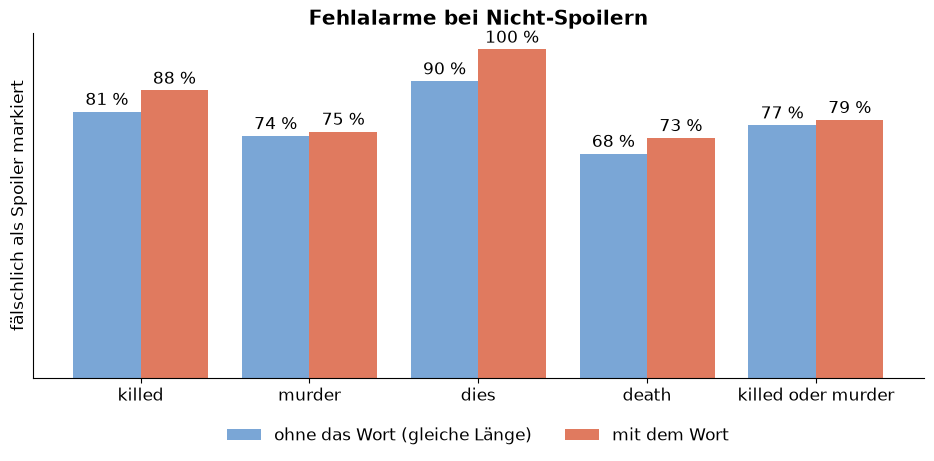

Nicht-Spoiler mit 'killed' oder 'murder':   14
Fehlalarme mit dem Wort:                    79 %
Fehlalarme ohne das Wort, gleiche Länge:    77 %
Verhältnis:                                 1.02   (95 %: 0.86 bis 1.20)


In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
x = np.arange(len(h3))

bars_a = ax.bar(x - 0.2, h3["ohne das Wort (gleiche Länge)"], 0.4, color=LIGHT,
                label="ohne das Wort (gleiche Länge)")
bars_b = ax.bar(x + 0.2, h3["mit dem Wort"], 0.4, color=RED, label="mit dem Wort")
ax.bar_label(bars_a, fmt="%.0f %%", padding=2)
ax.bar_label(bars_b, fmt="%.0f %%", padding=2)

ax.set_xticks(x, h3.index)
ax.set(title="Fehlalarme bei Nicht-Spoilern", ylabel="fälschlich als Spoiler markiert",
       ylim=(0, 105), yticks=[])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2, frameon=False)
show(fig, "15_h3_fehlalarme")

has_word = negatives["text"].str.contains(WORD_GROUPS["killed oder murder"], case=False)
rng = np.random.default_rng(SEED)
ratios = []
for _ in range(300):
    i = rng.integers(0, len(negatives), len(negatives))
    a, b = false_alarm_rates(negatives.iloc[i], has_word.iloc[i])
    ratios.append(a / b)
low, high = np.nanquantile(ratios, [0.025, 0.975])

with_rate = h3.at["killed oder murder", "mit dem Wort"]
without_rate = h3.at["killed oder murder", "ohne das Wort (gleiche Länge)"]
print(f"Nicht-Spoiler mit 'killed' oder 'murder':   {has_word.sum():,}")
print(f"Fehlalarme mit dem Wort:                    {with_rate:.0f} %")
print(f"Fehlalarme ohne das Wort, gleiche Länge:    {without_rate:.0f} %")
print(f"Verhältnis:                                 {with_rate / without_rate:.2f}"
      f"   (95 %: {low:.2f} bis {high:.2f})")

messwerte["H3 · Fehlalarme mit killed/murder"] = f"{with_rate:.0f} %"
messwerte["H3 · Fehlalarme ohne, gleiche Länge"] = f"{without_rate:.0f} %"
messwerte["H3 · Verhältnis"] = f"{with_rate / without_rate:.2f}  ({low:.2f} bis {high:.2f})"

## 7 · Übersicht der Messwerte

Zum Schluss sammeln wir die wichtigsten Zahlen in einer Tabelle. Sie wird als `figures/messwerte.csv` gespeichert, ebenso wie alle Abbildungen (300 dpi) und die vollständige Ergebnistabelle (`figures/ergebnisse.csv`).

Die Einordnung dieser Zahlen steht in der Dokumentation.

In [ ]:
overview = pd.DataFrame({"Wert": messwerte}).rename_axis("Messgröße")
overview.to_csv(FIG_DIR / "messwerte.csv")
display(overview)

,Wert
Messgröße,
"3 · Accuracy (unbekannte Filme, TF-IDF, LogReg)",0.668
"3 · Precision (unbekannte Filme, TF-IDF, LogReg)",0.388
"3 · Recall (unbekannte Filme, TF-IDF, LogReg)",0.680
"3 · F1 (unbekannte Filme, TF-IDF, LogReg)",0.494
"3 · ROC-AUC (unbekannte Filme, TF-IDF, LogReg)",0.713
3 · F1-Vorsprung auf „immer Spoiler“,+0.109 (+0.063 bis +0.153)
3 · F1 mit Spoiler-Wort (zum Vergleich),0.501
3 · ROC-AUC mit Spoiler-Wort (zum Vergleich),0.720
"3 · F1, Training „nur dieses Genre“",0.449
